# Assignment 4: Random Forests for Network Intrusion Detection

## Library and Data Imports

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utils
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold

In [8]:
features_df = pd.read_csv('features.csv')
network_traffic_df = pd.read_csv('networkTraffic.csv', na_values='?')
attack_df = pd.read_csv('attack_category_map.csv')

In [3]:
RANDOM_STATE=10

## Data Preprocessing (aligns to that of the classification tree)

In [9]:
# drop id column
network_traffic_df = network_traffic_df.drop(columns='id')

# fix issues in features_df
features_df.columns = features_df.columns.str.strip()
features_df['Name'] = features_df['Name'].str.lower()

# split numerical and categorical columns
is_numeric = lambda col: features_df[features_df['Name'] == col]['Type'].values in ['Float', 'Integer', 'integer']
numeric = [col for col in network_traffic_df.columns if is_numeric(col) and col != 'attack_cat'] + ['rate']
categorical = [col for col in network_traffic_df.columns if col not in numeric and col != 'attack_cat' and col != 'rate']

/var/folders/pr/05vbp6_94f3300tknkj0jbw40000gn/T/ipykernel_3190/1250961649.py:9: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  is_numeric = lambda col: features_df[features_df['Name'] == col]['Type'].values in ['Float', 'Integer', 'integer']


In [10]:
wrongly_numeric = []

In [11]:
# drop service column, put service_missing indicator in its place (because it is 54.8% missing
network_traffic_df['service_missing'] = network_traffic_df['service'].isna().astype(int)
network_traffic_df = network_traffic_df.drop(columns=['service'])

## Model

In [13]:
nominal_cols = categorical + ['service_missing']
nom_idx = [network_traffic_df.columns.get_loc(col) for col in nominal_cols if col in network_traffic_df.columns]


In [14]:
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score
from tempfile import mkdtemp
from shutil import rmtree
import numpy as np

cache_dir = mkdtemp()
X, y = network_traffic_df.drop(columns=['attack_cat']), network_traffic_df['attack_cat']

nominal_cols = categorical + ['service_missing']
nom_idx = [X.columns.get_loc(c) for c in nominal_cols if c in X.columns]

# SMOTE-NC dropped to prevent contamination of OOB estimates
preprocessor = ColumnTransformer(
    transformers=[('onehotencode', OneHotEncoder(handle_unknown='ignore'), nom_idx)],
    remainder='passthrough'
)

param_grid = {
    'classifier__max_features': ['sqrt', 'log2', 0.3],
    'classifier__min_samples_leaf': [1, 3, 10],
    'classifier__max_depth': [None, 20],
    'classifier__class_weight': [None, 'balanced_subsample'],
}

def oob_f1_macro(rf, y):
    # out of bag f1 macro estimate
    oob_pred = rf.classes_[np.argmax(rf.oob_decision_function_, axis=1)]
    return f1_score(y, oob_pred, average='macro')

results = []
for params in ParameterGrid(param_grid):
    pipeline = Pipeline(steps=[
        ('preprocess', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            bootstrap=True,
            oob_score=True,
            n_jobs=-1,
            random_state=RANDOM_STATE))
    ], memory=cache_dir)
    pipeline.set_params(**params)
    pipeline.fit(X, y)

    score = oob_f1_macro(pipeline.named_steps['classifier'], y)
    results.append((params, score, pipeline))
    print(params, f"OOB macro-F1: {score:.4f}")

best_params, best_score, best_rf_model = max(results, key=lambda r: r[1])
print(best_params)
print(best_score)
rmtree(cache_dir)

{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1} OOB macro-F1: 0.5572
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3} OOB macro-F1: 0.5335
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 10} OOB macro-F1: 0.4889
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 1} OOB macro-F1: 0.5485
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 3} OOB macro-F1: 0.5054
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 10} OOB macro-F1: 0.4524
{'classifier__class_weight': None, 'classifier__ma

In [15]:
best_params

{'classifier__class_weight': 'balanced_subsample',
 'classifier__max_depth': None,
 'classifier__max_features': 0.3,
 'classifier__min_samples_leaf': 3}

In [16]:
best_score

0.6223010665904923

In [17]:
best_rf_model

Pipeline(memory='/var/folders/pr/05vbp6_94f3300tknkj0jbw40000gn/T/tmpplxkgham',
         steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencode',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  [1, 2, 35, 40, 41])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_features=0.3, min_samples_leaf=3,
                                        n_estimators=300, n_jobs=-1,
                                        oob_score=True, random_state=10))])

# Performance metrics (OOB)

In [34]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

mapping = pd.read_csv('attack_category_map.csv')
name_map = dict(zip(mapping['Mapping'], mapping['Attack Category Name']))
rf = best_rf_model.named_steps['classifier']
y_oob_pred = rf.classes_[np.argmax(rf.oob_decision_function_, axis=1)]
class_names = [name_map.get(c, c) for c in rf.classes_]
classification_report = classification_report(y, y_oob_pred, labels=rf.classes_,target_names=class_names, digits=4, output_dict=True)


In [35]:
classification_report = pd.DataFrame(classification_report)

In [36]:
classification_report.columns = ['Normal','Reconnaissance',
'Backdoor',
'DoS',
'Exploits',
'Analysis',
'Fuzzers',
'Worms',
'Shellcode',
'Generic', 'ACCURACY', 'MACRO AVG', 'WEIGHTED AVG'
]

<Axes: >

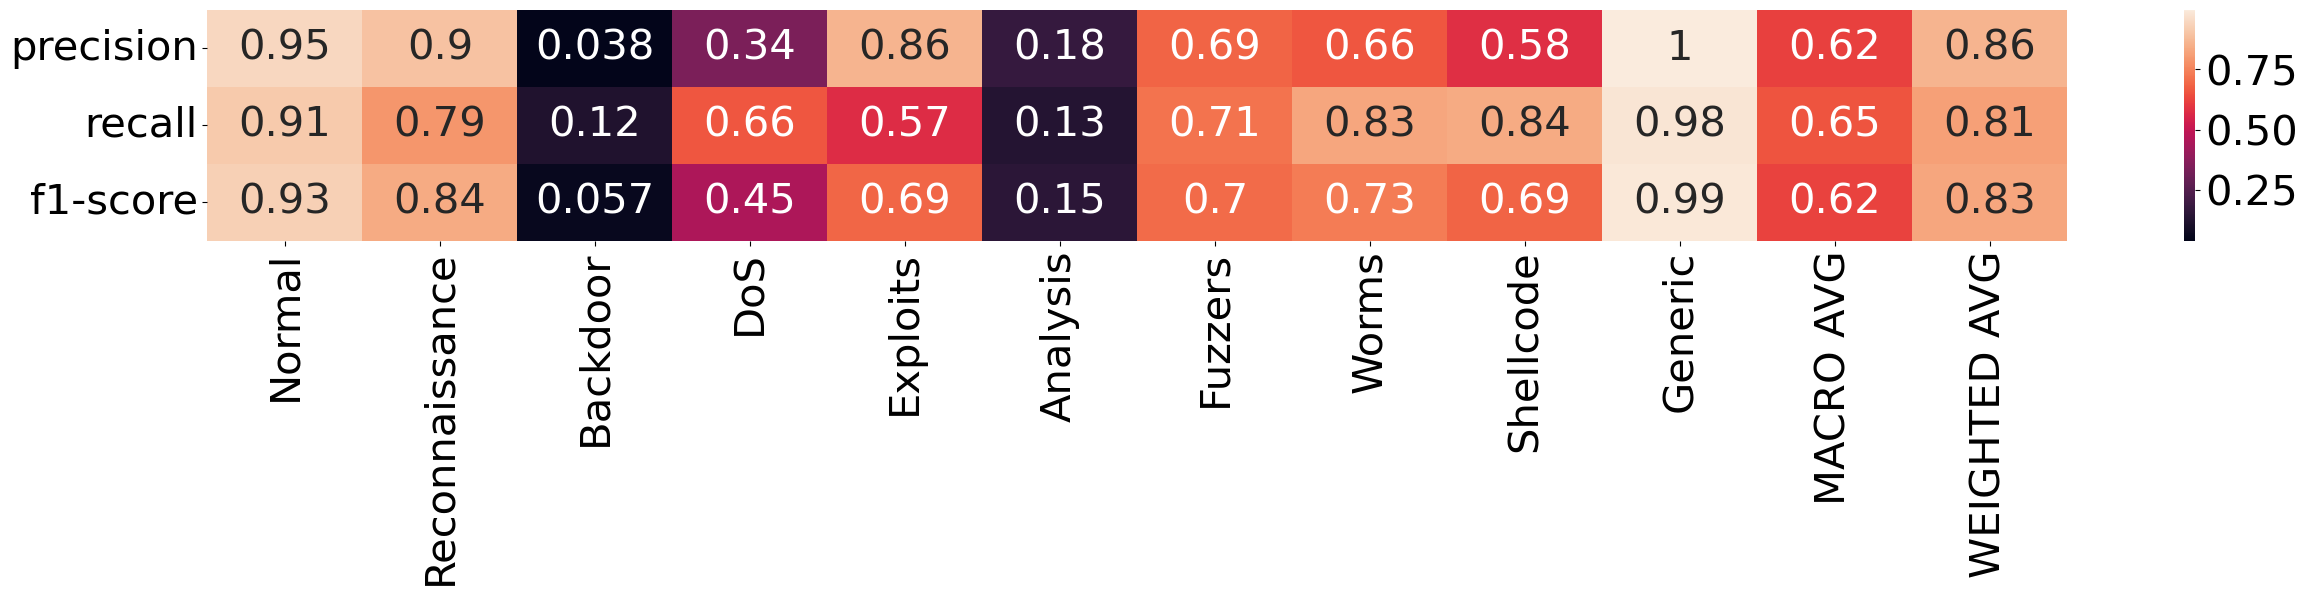

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(30,3))
plt.rc('font', size=30)
sns.heatmap(classification_report.iloc[[0,1,2]].drop(columns=['ACCURACY']), annot=True,)

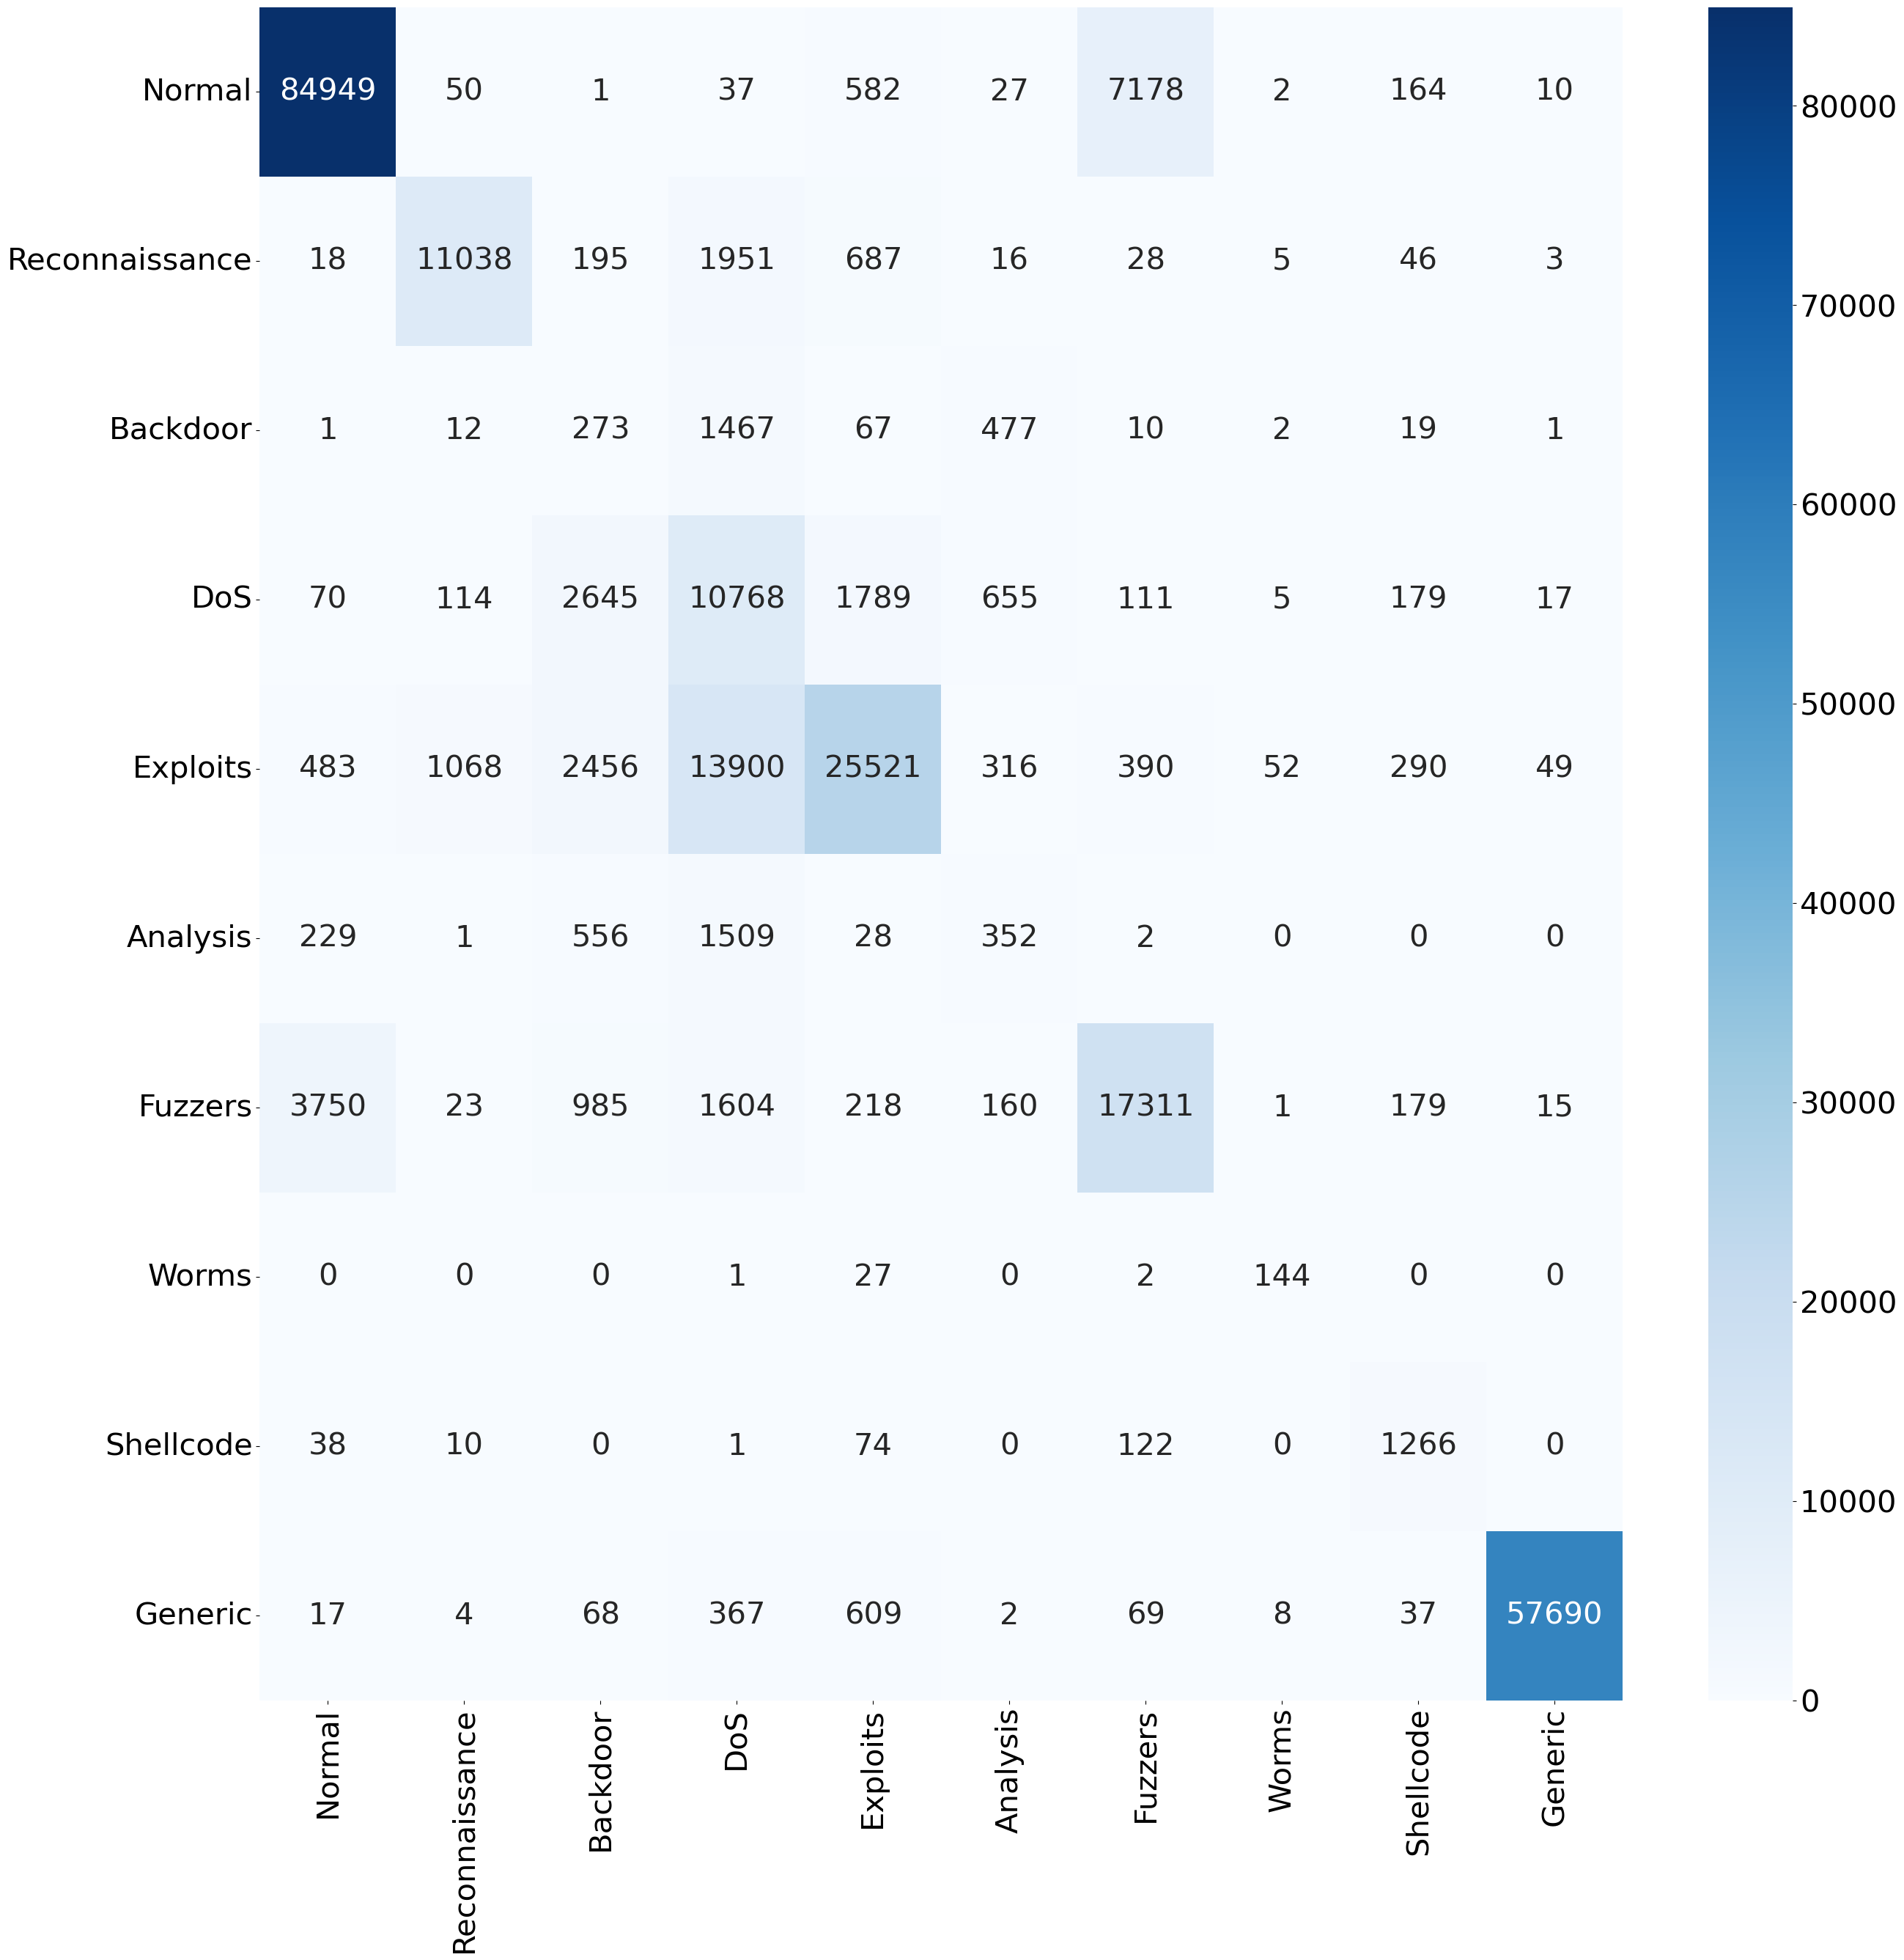

In [42]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, y_oob_pred)
plt.figure(figsize=(30,30))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=mapping['Attack Category Name'],
            yticklabels=mapping['Attack Category Name'])
plt.rc('font', size=30)

In [40]:
cm

array([[84949,    50,     1,    37,   582,    27,  7178,     2,   164,
           10],
       [   18, 11038,   195,  1951,   687,    16,    28,     5,    46,
            3],
       [    1,    12,   273,  1467,    67,   477,    10,     2,    19,
            1],
       [   70,   114,  2645, 10768,  1789,   655,   111,     5,   179,
           17],
       [  483,  1068,  2456, 13900, 25521,   316,   390,    52,   290,
           49],
       [  229,     1,   556,  1509,    28,   352,     2,     0,     0,
            0],
       [ 3750,    23,   985,  1604,   218,   160, 17311,     1,   179,
           15],
       [    0,     0,     0,     1,    27,     0,     2,   144,     0,
            0],
       [   38,    10,     0,     1,    74,     0,   122,     0,  1266,
            0],
       [   17,     4,    68,   367,   609,     2,    69,     8,    37,
        57690]])

In [43]:
# computing permutation importance
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
pi_model = clone(best_rf_model).set_params(memory=None)
pi_model.fit(X_tr, y_tr)
X_pi, _, y_pi, _ = train_test_split(
    X_val, y_val, train_size=20000, stratify=y_val, random_state=RANDOM_STATE)
pi = permutation_importance(pi_model, X_pi, y_pi, scoring='f1_macro',
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({'feature': X.columns,
                            'mean': pi.importances_mean,
                            'std': pi.importances_std})
              .sort_values('mean', ascending=False))
print(importance.head(15))

              feature      mean       std
5              sbytes  0.130671  0.005820
8                sttl  0.112605  0.006158
41    service_missing  0.105688  0.007065
25              smean  0.067105  0.007309
34     ct_dst_src_ltm  0.017536  0.002558
26              dmean  0.014348  0.002116
23             synack  0.013577  0.005818
39         ct_srv_dst  0.012968  0.001773
6              dbytes  0.010926  0.003240
28  response_body_len  0.010288  0.000272
37   ct_flw_http_mthd  0.009060  0.000408
1               proto  0.006725  0.002294
24             ackdat  0.004866  0.000736
27        trans_depth  0.004616  0.000302
20              dtcpb  0.004313  0.002090


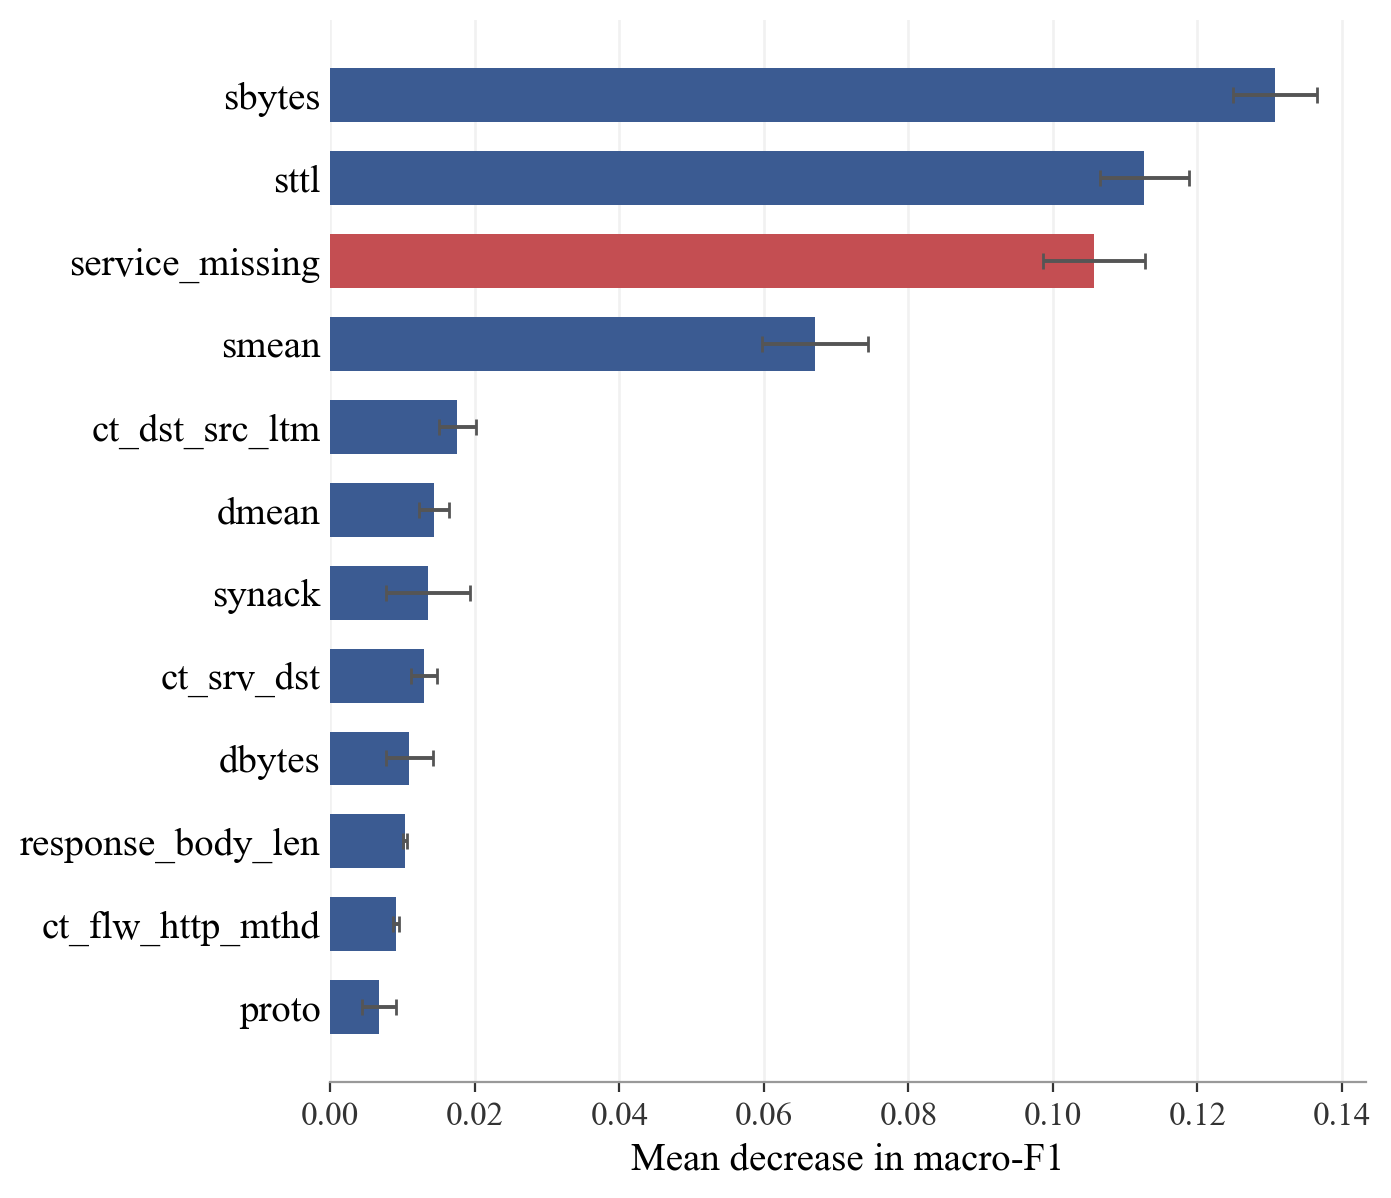

In [45]:
import matplotlib.pyplot as plt

def plot_permutation_importance(importance, filename_stem, top_n=12, width=7,
                                highlight=None, show_values=False):
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
        'pdf.fonttype': 42,
        'svg.fonttype': 'none',
        'figure.dpi': 200,
    })
    top = importance.sort_values('mean', ascending=False).head(top_n).iloc[::-1]
    highlight = set(highlight or [])
    colors = ['#C44E52' if f in highlight else '#3B5B92' for f in top['feature']]
    height = 0.42 * len(top) + 1.0
    fig,ax = plt.subplots(figsize=(width, height))
    ax.barh(top['feature'], top['mean'], xerr=top['std'], color=colors,
            height=0.65, zorder=2,
            error_kw={'elinewidth': 1.4, 'capsize': 3, 'ecolor': '#555555'})
    if show_values:
        for i, (m,s) in enumerate(zip(top['mean'], top['std'])):
            ax.text(m+s+top['mean'].max()*0.02, i, f'{m:.3f}',
                    va='center', fontsize=12, color='#333333')
        ax.set_xlim(right=top['mean'].max() * 1.22)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#999999')
    ax.tick_params(axis='y', length=0, labelsize=14)
    ax.tick_params(axis='x', labelsize=12, colors='#333333')
    ax.xaxis.grid(True, color='#E5E5E5', linewidth=1, zorder=0)
    ax.set_xlabel('Mean decrease in macro-F1', fontsize=14)
    ax.set_xlim(left=0)
    plt.tight_layout(pad=0.3)
    plt.savefig(f'{filename_stem}.svg', bbox_inches='tight')
    plt.savefig(f'{filename_stem}.png', bbox_inches='tight', dpi=600)
    plt.show()

plot_permutation_importance(importance, 'rf_permutation_importance',
                            highlight=['service_missing'])